# Blink Hunters: finding moving and changing objects in SPHEREx data

**NASA Space Apps 2026 · Challenge: "Planet X and SPHEREx"**

This notebook reproduces, step by step, what the Blink Hunters web tool does, and checks its results on the
challenge's test targets: Barnard's Star, Epsilon Indi B, WISE 0855, RW Aurigae and R Draconis.

1. Resolve a target and correct for proper motion
2. Find every SPHEREx exposure covering it (DR1 + QR3)
3. Look inside one exposure (image, flags, zodiacal light, per-pixel wavelength)
4. Build per-visit stacks and **blink / difference** them
5. **Match wavelengths** across visits (SPHEREx's 102 channels)
6. **Spectra on the fly** from every exposure
7. **Brightness over time** (RW Aurigae)
8. **Position over time** (WISE 0855, blended with a background star)
9. Gaia DR3 check, and partner data from CSA's NEOSSat

The notebook reuses the app's pipeline (`backend/app/`). Views built earlier are cached in `cache/`, so it runs in
about a minute; on a fresh machine the first run downloads the stamps (several minutes per target).

> *Acknowledgement:* This publication makes use of data products from the Spectro-Photometer for the History of the
> Universe, Epoch of Reionization and Ices Explorer (SPHEREx), which is a joint project of the Jet Propulsion
> Laboratory and the California Institute of Technology, and is funded by the National Aeronautics and Space
> Administration. (DOIs 10.26131/IRSA678, 10.26131/IRSA679.) Gaia DR3: ESA/Gaia/DPAC. NEOSSat: Canadian Space Agency.
>
> *AI disclosure:* the code was written with an AI coding assistant (Claude) at the team's direction; see README.md.

## 0. Setup

In [1]:
import sys, json, io, warnings, logging
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "backend"))
warnings.filterwarnings("ignore")

import numpy as np
import matplotlib.pyplot as plt
from astropy.time import Time
from IPython.display import Image as IPImage, display
from PIL import Image

from app import archive, astrometry, config, fetch, frames, gaia, pipeline, resolve
logging.getLogger("astropy").setLevel(logging.ERROR)  # after astropy is imported

plt.rcParams.update({"figure.dpi": 110, "image.origin": "lower"})
print("project:", ROOT)
print("collections:", config.COLLECTIONS)

project: /Users/ktapas/spherex-blink-hunters
collections: ['spherex_dr1', 'spherex_qr3']


## 1. SPHEREx in one table

SPHEREx maps the whole sky about every 6 months from 0.75 to 5 µm. Six detectors each sit behind a
**linear variable filter**: the wavelength changes smoothly across the detector, so each exposure sees a star at a
slightly different wavelength. Seventeen channels per detector give the "102 bands". Pixels are large (6.15″).

In [2]:
for det, (lo, hi) in config.DETECTOR_BANDS.items():
    print(f"D{det}: {lo:.2f}-{hi:.2f} um   ({config.CHANNELS_PER_DETECTOR} channels)")
print("pixel scale:", config.PIXEL_SCALE_ARCSEC, "arcsec")

D1: 0.75-1.09 um   (17 channels)
D2: 1.10-1.62 um   (17 channels)
D3: 1.63-2.41 um   (17 channels)
D4: 2.42-3.82 um   (17 channels)
D5: 3.83-4.41 um   (17 channels)
D6: 4.42-5.00 um   (17 channels)
pixel scale: 6.15 arcsec


## 2. Targets and proper motion

Catalogue (J2000) positions of nearby stars are badly out of date. Barnard's Star has moved **4.5 arcminutes**
since 2000, more than half of a 6′ cutout. The app moves every target to epoch 2026.0 before searching.

In [3]:
targets = {p["label"]: resolve.resolve(p["query"]) for p in pipeline.PRESETS}
print(f"{'target':16s} {'pm (\"/yr)':>10s} {'moved since J2000':>20s}")
for label, t in targets.items():
    pm = np.hypot(t.pmra, t.pmdec) / 1000
    print(f"{label:16s} {pm:10.2f} {t.moved_arcsec:12.1f}\" = {t.moved_arcsec / config.PIXEL_SCALE_ARCSEC:4.1f} px")

target            pm ("/yr)    moved since J2000
Barnard's Star        10.39        270.2" = 43.9 px
Epsilon Indi B         4.68        121.8" = 19.8 px
WISE 0855              8.15        211.9" = 34.5 px
RW Aurigae             0.02          0.6" =  0.1 px
R Draconis             0.02          0.6" =  0.1 px


## 3. Every SPHEREx exposure of a target

A live query to IRSA (SIA, DR1 + QR3). Exposures are grouped into **visits**: clusters of dates separated by more
than 30 days, roughly every 6 months.

In [4]:
t = targets["Barnard's Star"]
exposures = archive.find_exposures(t.ra, t.dec)
visits = archive.visit_summary(exposures)
print(len(exposures), "exposures")
for v in visits:
    print(f"  visit {v['visit'] + 1}: {v['start']} -> {v['end']}  ({v['n']} exposures)")
dets = [e.detector for e in exposures]
print("per detector:", {f"D{d}": dets.count(d) for d in range(1, 7)})

358 exposures
  visit 1: 2025-08-15 -> 2025-10-01  (118 exposures)
  visit 2: 2026-03-11 -> 2026-05-05  (121 exposures)
  visit 3: 2026-08-16 -> 2026-09-22  (119 exposures)
per detector: {'D1': 60, 'D2': 61, 'D3': 59, 'D4': 59, 'D5': 61, 'D6': 58}


## 4. Inside one exposure

Each exposure has image, flags, variance, zodiacal-light and per-pixel wavelength layers. The app reads only a
small stamp around the target from the public AWS copy, skipping the big PSF cube that the cutout service always
sends (~4–5 MB per exposure).

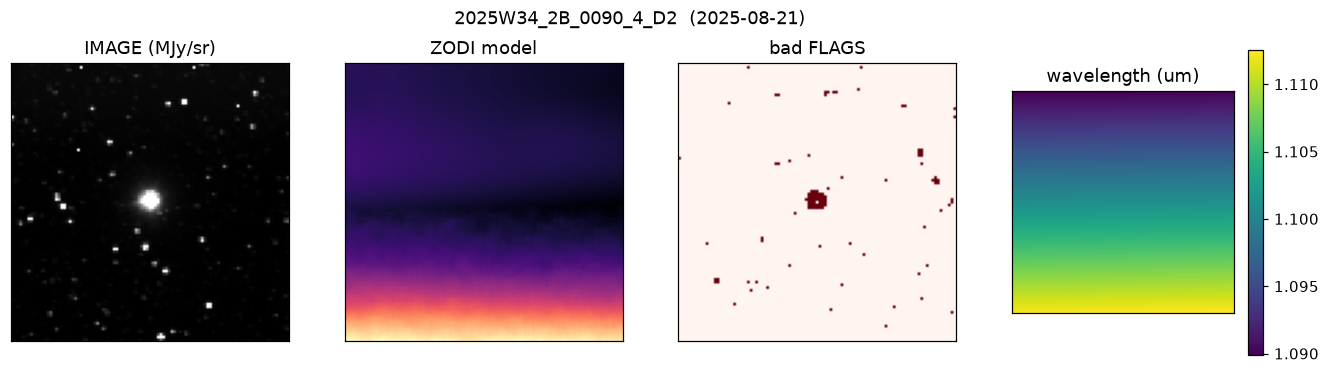

In [5]:
half = pipeline.stamp_half_size(0.1)
exp = next(e for e in exposures if e.detector == 2)
stamp = fetch.get_stamp(exp, t.ra, t.dec, half)
img, var = frames.clean(stamp)

fig, ax = plt.subplots(1, 4, figsize=(15, 3.6))
ax[0].imshow(stamp["image"], cmap="gray", vmin=np.nanpercentile(stamp["image"], 5), vmax=np.nanpercentile(stamp["image"], 99.5)); ax[0].set_title("IMAGE (MJy/sr)")
ax[1].imshow(stamp["zodi"], cmap="magma"); ax[1].set_title("ZODI model")
ax[2].imshow((stamp["flags"].astype(np.int64) & config.BAD_FLAG_MASK) != 0, cmap="Reds"); ax[2].set_title("bad FLAGS")
im = ax[3].imshow(stamp["wave"], cmap="viridis"); ax[3].set_title("wavelength (um)"); fig.colorbar(im, ax=ax[3])
for a in ax: a.set_xticks([]); a.set_yticks([])
plt.suptitle(f"{exp.key}  ({Time(exp.mjd, format='mjd').iso[:10]})"); plt.show()

## 5. Blink and difference: Barnard's Star

The app aligns every stamp onto one sky grid (zodi subtracted, bad flags masked, background levelled), stacks
each visit per detector with inverse-variance weights, and renders all frames with one shared brightness scale.
In the **difference** frames a moving star becomes a black/white pair.

view c65ccbc706ff | exposures used: 358 | frames: 321


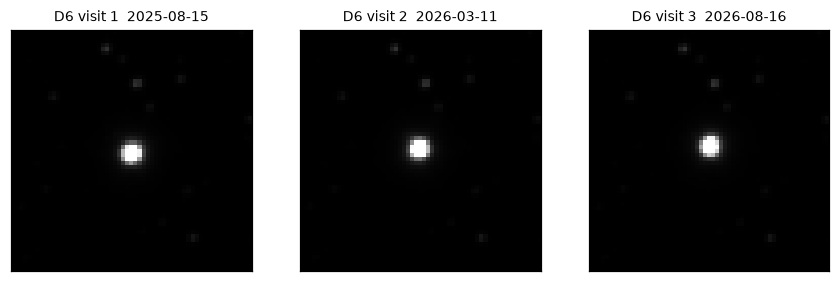

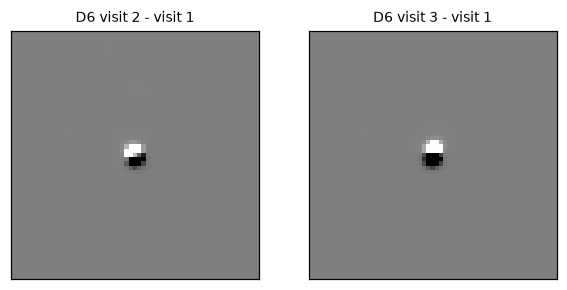

In [6]:
def build(label, per_group=0):
    key = pipeline.start_view(pipeline.PRESETS[[p["label"] for p in pipeline.PRESETS].index(label)]["query"], 0.1, per_group)
    state = pipeline.job(key)
    while state["status"] not in ("done", "error"):
        import time; time.sleep(2); state = pipeline.job(key)
    assert state["status"] == "done", state
    return key, state["manifest"]

def show_frames(key, m, files, titles, scale=4):
    fig, ax = plt.subplots(1, len(files), figsize=(3.2 * len(files), 3.4))
    for a, f, ti in zip(np.atleast_1d(ax), files, titles):
        a.imshow(np.asarray(Image.open(config.VIEW_DIR / key / f)), cmap="gray", origin="upper")
        a.set_title(ti, fontsize=9); a.set_xticks([]); a.set_yticks([])
    plt.show()

def gif(key, files, path, ms=600, scale=5):
    ims = [Image.open(config.VIEW_DIR / key / f).convert("L") for f in files]
    ims = [im.resize((im.width * scale, im.height * scale), Image.NEAREST) for im in ims]
    ims[0].save(path, save_all=True, append_images=ims[1:], duration=ms, loop=0)
    return IPImage(filename=str(path))

key_b, m_b = build("Barnard's Star")
print("view", key_b, "| exposures used:", m_b["n_exposures_used"], "| frames:", len(m_b["frames"]))
d6 = sorted([f for f in m_b["frames"] if f["group"] == "6"], key=lambda f: f["visit"])
show_frames(key_b, m_b, [f["file"] for f in d6], [f"D6 visit {f['visit'] + 1}  {f['start']}" for f in d6])
diffs = sorted([f for f in m_b["diffs"] if f["group"] == "6"], key=lambda f: f["visit"])
show_frames(key_b, m_b, [f["file"] for f in diffs], [f"D6 visit {f['visit'] + 1} - visit 1" for f in diffs])

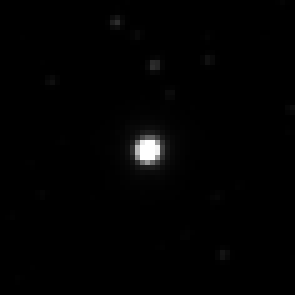

In [7]:
# The same blink as the web app shows it (animated GIF, saved next to this notebook)
display(gif(key_b, [f["file"] for f in d6], ROOT / "notebooks" / "barnard_D6_blink.gif"))

## 6. Matching wavelengths across visits

Within one detector the wavelength still varies a lot (D4 spans 2.4–3.8 µm). A Space Apps Navigator advised
matching wavelengths before blinking, so a colour difference isn't mistaken for motion or variability. The app splits
each detector into 17 log-wavelength channels and blinks only exposures from the same channel.

102 channels were observed in 2+ visits; D6 has 17:
  channel  1/17  4.436 um  visits [1, 2, 3]
  channel  2/17  4.468 um  visits [1, 2, 3]
  channel  3/17  4.501 um  visits [1, 2, 3]
  channel  4/17  4.534 um  visits [2, 3]
  channel  5/17  4.567 um  visits [1, 2, 3]
  channel  6/17  4.600 um  visits [1, 2, 3]
  channel  7/17  4.633 um  visits [1, 2, 3]
  channel  8/17  4.667 um  visits [1, 2, 3]
  channel  9/17  4.701 um  visits [1, 2, 3]
  channel 10/17  4.735 um  visits [1, 2, 3]
  channel 11/17  4.770 um  visits [1, 2, 3]
  channel 12/17  4.804 um  visits [1, 2, 3]
  channel 13/17  4.839 um  visits [1, 2, 3]
  channel 14/17  4.875 um  visits [1, 2, 3]
  channel 15/17  4.910 um  visits [2, 3]
  channel 16/17  4.946 um  visits [1, 2, 3]
  channel 17/17  4.982 um  visits [1, 2, 3]


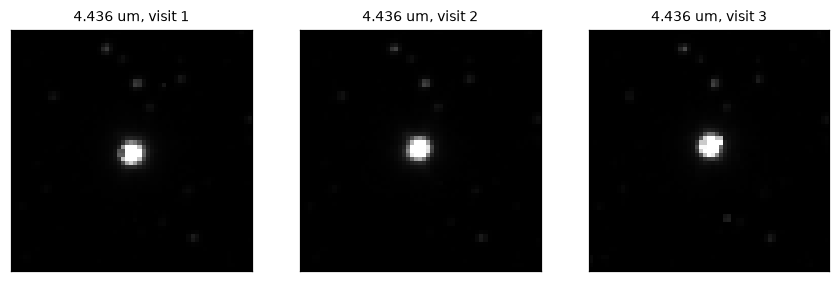

In [8]:
chans = [c for c in m_b["channels"] if c["detector"] == 6]
print(f"{len(m_b['channels'])} channels were observed in 2+ visits; D6 has {len(chans)}:")
for c in chans:
    print(f"  channel {c['channel'] + 1:2d}/17  {c['wl_center']:.3f} um  visits {[v + 1 for v in c['visits']]}")
best = max(chans, key=lambda c: len(c["visits"]))
fr = sorted([f for f in m_b["frames"] if f["group"] == best["group"]], key=lambda f: f["visit"])
show_frames(key_b, m_b, [f["file"] for f in fr], [f"{best['wl_center']:.3f} um, visit {f['visit'] + 1}" for f in fr])

## 7. Spectra on the fly

Clicking any object measures it in every exposure (aperture photometry, local background subtracted), giving a
spectrum of up to 102 wavelengths. Barnard's Star itself is saturated (flagged) in almost every exposure, so here
is a field star in the same view.

field star: 347 points (8 flagged) | Barnard's Star: 21 points (337 flagged = saturated)


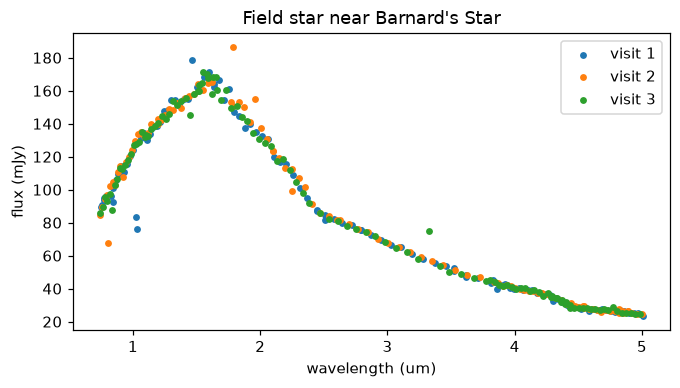

In [9]:
w, shape = frames.grid_wcs(m_b["target"]["ra"], m_b["target"]["dec"], m_b["fov_deg"])
s = np.load(config.VIEW_DIR / key_b / "stack_Dall.npz")["v0"]
n = shape[0]; c = n // 2; yy, xx = np.indices(s.shape)
s2 = np.where(np.isfinite(s), s, -np.inf); s2[np.hypot(xx - c, yy - c) < 8] = -np.inf
s2[:8] = s2[-8:] = -np.inf; s2[:, :8] = s2[:, -8:] = -np.inf
y, x = np.unravel_index(np.argmax(s2), s.shape)
star = w.pixel_to_world(x, y)

pts, flagged = pipeline.view_spectrum(key_b, star.ra.deg, star.dec.deg)
pts_b, flagged_b = pipeline.view_spectrum(key_b, m_b["target"]["ra"], m_b["target"]["dec"])
print(f"field star: {len(pts)} points ({flagged} flagged) | Barnard's Star: {len(pts_b)} points ({flagged_b} flagged = saturated)")

fig, ax = plt.subplots(figsize=(7, 3.5))
for v in sorted({p["visit"] for p in pts}):
    q = [p for p in pts if p["visit"] == v]
    ax.scatter([p["wavelength_um"] for p in q], [p["flux_mjy"] for p in q], s=12, label=f"visit {v + 1}")
ax.set_xlabel("wavelength (um)"); ax.set_ylabel("flux (mJy)"); ax.set_title("Field star near Barnard's Star"); ax.legend(); plt.show()

## 8. Brightness over time: RW Aurigae

RW Aur is a young star with a dusty disk. Between visits it gets **brighter at short wavelengths and fainter at
4–5 µm**, a colour change, which is why comparing within one detector (or channel) matters.

237 points; 96 flagged (D4 saturates)


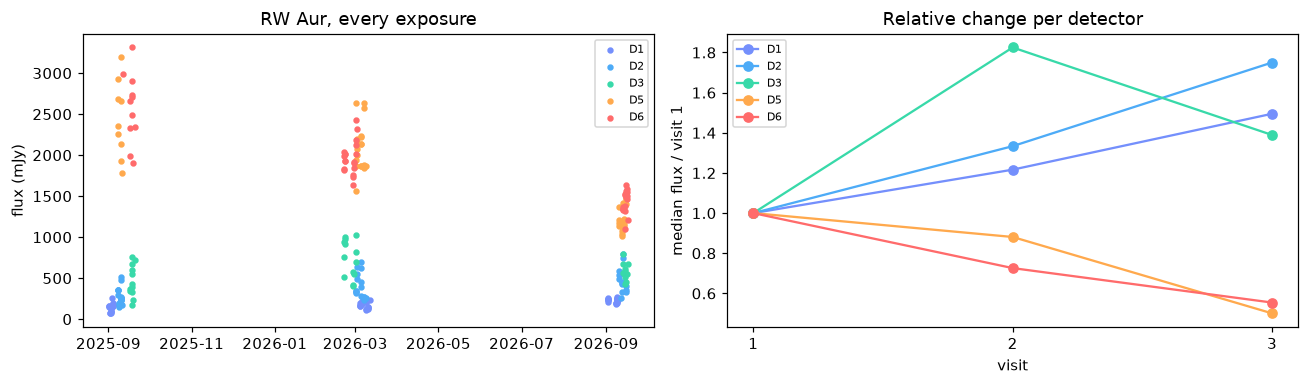

In [10]:
key_r, m_r = build("RW Aurigae")
pts_r, flagged_r = pipeline.view_spectrum(key_r, m_r["target"]["ra"], m_r["target"]["dec"])
print(len(pts_r), "points;", flagged_r, "flagged (D4 saturates)")
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
for det, col in [(1, "#748ffc"), (2, "#4dabf7"), (3, "#38d9a9"), (5, "#ffa94d"), (6, "#ff6b6b")]:
    q = [p for p in pts_r if p["detector"] == det]
    if not q: continue
    t_ = Time([p["mjd"] for p in q], format="mjd").datetime
    ax[0].scatter(t_, [p["flux_mjy"] for p in q], s=10, color=col, label=f"D{det}")
    med = [np.median([p["flux_mjy"] for p in q if p["visit"] == v]) for v in sorted({p["visit"] for p in q})]
    ax[1].plot(range(1, len(med) + 1), np.array(med) / med[0], "o-", color=col, label=f"D{det}")
ax[0].set_ylabel("flux (mJy)"); ax[0].set_title("RW Aur, every exposure"); ax[0].legend(fontsize=7)
ax[1].set_xticks([1, 2, 3]); ax[1].set_xlabel("visit"); ax[1].set_ylabel("median flux / visit 1"); ax[1].set_title("Relative change per detector"); ax[1].legend(fontsize=7)
plt.tight_layout(); plt.show()

## 9. Position over time: WISE 0855, the coldest known brown dwarf

WISE 0855 moves 8.1″/yr but is almost invisible below ~3.5 µm. In SPHEREx it shares a pixel with a background
star (Gaia G = 16.3, 6.8″ away). The **light centre** shows the blend:
- **D1–D4** (short wavelengths, the background star): fixed.
- **D5–D6** (4–5 µm, the brown dwarf): drifts west by about 5″ in a year (diluted by the blend).

The spectrum at that spot shows the brown dwarf's 4–5 µm peak.

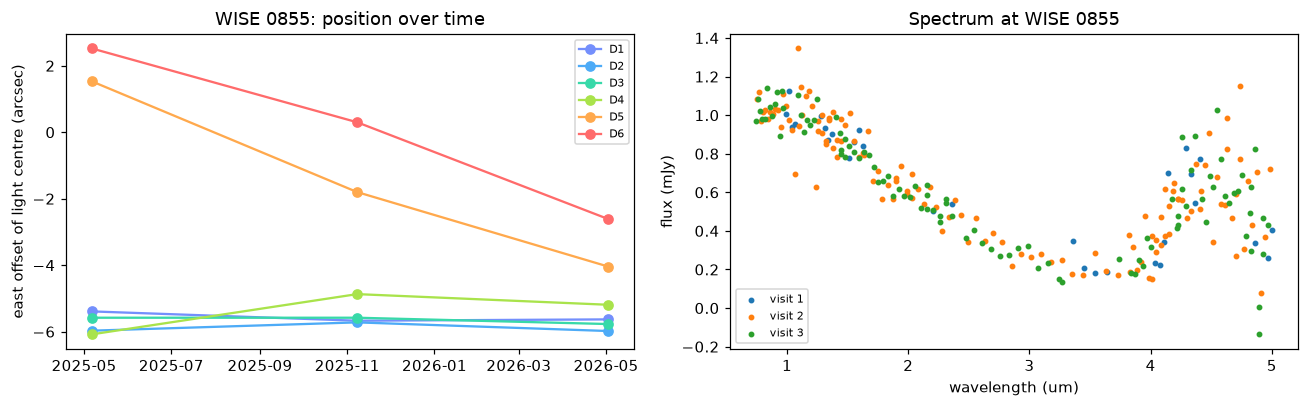

D1: east offsets [-5.39, -5.67, -5.63]
D6: east offsets [2.52, 0.3, -2.61]


In [11]:
key_w, m_w = build("WISE 0855")
tw = m_w["target"]
pos = astrometry.positions(config.VIEW_DIR / key_w, tw["ra"], tw["dec"])
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
cols = {1: "#748ffc", 2: "#4dabf7", 3: "#38d9a9", 4: "#a9e34b", 5: "#ffa94d", 6: "#ff6b6b"}
for det in range(1, 7):
    q = sorted([p for p in pos if p["detector"] == det], key=lambda p: p["mjd"])
    ax[0].plot(Time([p["mjd"] for p in q], format="mjd").datetime, [p["east_arcsec"] for p in q], "o-", color=cols[det], label=f"D{det}")
ax[0].set_ylabel("east offset of light centre (arcsec)"); ax[0].set_title("WISE 0855: position over time"); ax[0].legend(fontsize=7)
pts_w, _ = pipeline.view_spectrum(key_w, tw["ra"], tw["dec"])
for v in sorted({p["visit"] for p in pts_w}):
    q = [p for p in pts_w if p["visit"] == v]
    ax[1].scatter([p["wavelength_um"] for p in q], [p["flux_mjy"] for p in q], s=8, label=f"visit {v + 1}")
ax[1].set_xlabel("wavelength (um)"); ax[1].set_ylabel("flux (mJy)"); ax[1].set_title("Spectrum at WISE 0855"); ax[1].legend(fontsize=7)
plt.tight_layout(); plt.show()
for det in (1, 6):
    q = sorted([p for p in pos if p["detector"] == det], key=lambda p: p["mjd"])
    print(f"D{det}: east offsets", [p["east_arcsec"] for p in q])

## 10. Cross-check with Gaia DR3

Gaia stars, moved from epoch 2016.0 to 2026.0, should land on the SPHEREx stars. That tests our alignment, and
Gaia's proper motion for Barnard's Star predicts the motion seen in the difference images.

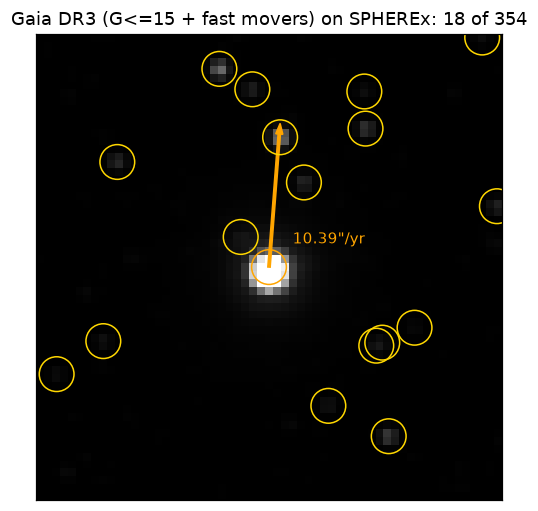

In [12]:
src = gaia.sources_for_view(config.VIEW_DIR / key_b, m_b)
bright = [s for s in src if s["g"] <= 15 or s["fast"]]
img = np.asarray(Image.open(config.VIEW_DIR / key_b / "Dall_v0.png"))
n = img.shape[0]
fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.imshow(img, cmap="gray", origin="upper")
for s in bright:
    ax.add_patch(plt.Circle((s["x"], n - 1 - s["y"]), 2.2, fill=False, color="orange" if s["fast"] else "gold", lw=1))
    if s["fast"]:
        ax.arrow(s["x"], n - 1 - s["y"], s["dx_per_yr"] * 10, -s["dy_per_yr"] * 10, color="orange", width=0.3)
        ax.text(s["x"] + 3, n - 1 - s["y"] - 3, f"{s['pm'] / 1000:.2f}\"/yr", color="orange")
ax.set_xlim(-0.5, n - 0.5); ax.set_ylim(n - 0.5, -0.5)
ax.set_title(f"Gaia DR3 (G<=15 + fast movers) on SPHEREx: {len(bright)} of {len(src)}"); ax.set_xticks([]); ax.set_yticks([]); plt.show()

## 11. Partner data: CSA NEOSSat

NEOSSat (Canadian Space Agency) is an optical space telescope for asteroids and comets. Its images, archived at the
Canadian Astronomy Data Centre, cover all five test targets (about 2019–2023). Together with SPHEREx (2025–2026)
that's a ~6-year baseline. The query takes ~40 s per target, so only Barnard's Star is run here.

In [13]:
import astropy.units as u
from astropy.coordinates import SkyCoord
from astroquery.cadc import Cadc
r = Cadc().query_region(SkyCoord(t.ra, t.dec, unit="deg"), radius=0.5 * u.deg, collection="NEOSSAT")
years = sorted({Time(x, format="mjd").jyear // 1 for x in r["time_bounds_lower"]})
print(f"NEOSSat images within 0.5 deg of Barnard's Star: {len(r)}; years {[int(y) for y in years]}")

NEOSSat images within 0.5 deg of Barnard's Star: 662; years [2018, 2019, 2021, 2022, 2026]


## Summary

| Test target | What SPHEREx shows (this notebook) |
|---|---|
| Barnard's Star | 10.4″/yr motion: clear black/white pair in difference images; matches Gaia. Core saturated. |
| Epsilon Indi B | 4 visits; moving brown-dwarf pair (~1 px/yr) |
| WISE 0855 | Detected only at 4–5 µm, blended with a background star; light centre drifts west in D5/D6 only |
| RW Aurigae | Colour-dependent variability: brighter at 1–2 µm, fainter at 4–5 µm across visits |
| R Draconis | Saturated in all exposures; variability visible only by eye in blinks |

All changes are **candidates**: check flags, compare within one detector or channel, and confirm with other data
(Gaia, NEOSSat, WISE) before calling anything a discovery.